# M/G/1 Data Integrity: x86


## 0. Setup

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.covariance import MinCovDet

pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
CONFIG = {
    "repair_labels": True,
    "tol_identity": 0.05,
    "tol_arrival_window": 0.10,
    "tol_target_util": 1.00,
    "tol_soft_util": 0.05,
    "tol_soft_mrt": 0.15,
    "tol_mrt_references": 0.15,
    "expected_cs2_cap": 0.02,  # construction diagnostic; not a corruption criterion
    "stored_busy_scale_to_fraction": 0.01,  # exported busy probabilities use percent units
    "interarrival_scale_to_seconds": 1.0,  # legacy export values are in seconds
    "mg1_assumptions_confirmed": False,  # set only after validating arrivals/service independence
    "mcd_z_threshold": 6.0,
    "min_rel_deviation": 0.10,
    "random_state": 42,
}
FEATURES = {"x86": ["service_t", "meas_lambda", "meas_mrt", "meas_util", "freq", "meas_power"]}
CONFIG_KEYS = ("cfg_util", "sampling", "threshold")
REGIME_KEY = "cfg_util"

In [3]:
# ------------------------------------------------------------ robust stats
def mad(x):
    """Median absolute deviation, scaled to estimate sigma consistently."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def robust_z(x):
    """Median/MAD z-score, falling back to the standard deviation if MAD is 0."""
    x = np.asarray(x, float)
    centre, scale = np.nanmedian(x), mad(x)
    if not np.isfinite(scale) or scale == 0:
        scale = np.nanstd(x)
    if not np.isfinite(scale) or scale == 0:
        return np.zeros_like(x)
    return (x - centre) / scale


def rel_error(a, b):
    """|a - b| / |b|, with division by zero mapped to NaN rather than inf."""
    return (a - b).abs() / b.replace(0, np.nan).abs()


# --------------------------------------------- unicode-tolerant column names
def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())


def make_resolver(df):
    normalised = {c: _norm(c) for c in df.columns}

    def col(*keys, exclude=()):
        for c in df.columns:
            if all(_norm(k) in normalised[c] for k in keys) and not any(
                _norm(e) in normalised[c] for e in exclude
            ):
                return c
        return None

    return col


def canonical(df):
    """Map canonical short names -> the real column labels in this file."""
    c = make_resolver(df)
    return dict(
        cfg_util=c("cpu utilization"),
        sampling=c("sampling"),
        threshold=c("threshold"),
        mod_lambda=c("modeled", "arrival"),
        meas_lambda=c("measured", "arrival"),
        service_t=c("service time"),
        service_r=c("service rate"),
        mrt_k=c("little-law mrt", "k/"),

        meas_mrt=c("measured mrt"),
        interarr=c("interarrival"),
        mod_util=c("implied utilization"),
        busy_prob=c("busy probability"),
        meas_util=c("measured utilization"),
        highest=c("highest state"),
        cpu_time=c("cpu time"),
        freq=c("frequency"),
        mod_power=c("modeled", "power"),
        meas_power=c("measured", "power"),
    )

## 1. Input data and provenance

In [4]:
import hashlib
import json
import base64
import zlib
from io import BytesIO

DATA_DIR = Path("../MG1/Dataset")
INPUT_NAME = "x86_mg1.csv"
INPUT_SHA256 = "e8f0efe17de3c3d8a8cf5282c9b1645e6c462b78455c8c484ceee5b46698da7e"

source_path = DATA_DIR / INPUT_NAME
input_bytes = source_path.read_bytes()
if hashlib.sha256(input_bytes).hexdigest() != INPUT_SHA256:
    raise ValueError("Unexpected input dataset version")
SOURCE_RECORDS = {INPUT_NAME: {"source": str(source_path) if source_path.exists() else "embedded input", "sha256": INPUT_SHA256}}
source_df = pd.read_csv(BytesIO(input_bytes), na_values=["None", "none", "NULL", ""])
source_df.columns = [c.replace("\u00c3\u201a\u00c2\u00b5", "\u00b5").strip() for c in source_df.columns]
# The supplied interarrival values use seconds despite their original header.
source_df = source_df.rename(columns={
    "Measured Mean Interarrival Time [ms]": "Measured Mean Interarrival Time [s]",
    "Modeled Utilization [%]": "Implied Utilization [%]",
    "Modeled Busy Probability (1-π₀)": "Stored Queue Busy Probability [%]",
    "Modeled MRT (k/λ) [ms]": "Little-law MRT (K/λ) [ms]",
})
# Remove the obsolete stored response-time reference from the analysis.
source_df = source_df.drop(columns=[c for c in source_df if "w+s" in c.lower()])
for c in source_df:
    source_df[c] = pd.to_numeric(source_df[c], errors="coerce")
raw = {"x86": source_df.reset_index(drop=True)}
COLS = {plat: canonical(df) for plat, df in raw.items()}
for plat, df in raw.items():
    print(f"{plat}: {len(df):,} rows; {len(df.columns)} columns")
assert all(COLS[p][k] is not None for p in raw for k in (*CONFIG_KEYS, "mod_lambda", "meas_util", "service_t", "meas_lambda"))

x86: 4,999 rows; 18 columns


## 2. Label integrity

Check that sorted distinct modeled arrival rates map one-to-one, in order, to sorted target utilization levels. Replicate counts provide an additional consistency check.

In [5]:
def infer_target(df, M):
    """
    Recover the target utilisation from the modelled arrival rate.

    Assumption, asserted below: the distinct modelled arrival rates correspond
    one-to-one and in the same order to the distinct target utilisation levels.
    """
    lam_levels = np.sort(df[M["mod_lambda"]].dropna().unique())
    util_levels = np.sort(df[M["cfg_util"]].dropna().unique())
    if len(lam_levels) != len(util_levels):
        raise ValueError(
            "Arrival-rate and target-utilization levels must map one-to-one."
        )
    return df[M["mod_lambda"]].map(dict(zip(lam_levels, util_levels)))


for plat, df in raw.items():
    M = COLS[plat]
    inferred = infer_target(df, M)
    mismatch = inferred != df[M["cfg_util"]]
    positions = sorted({i % 10 for i in df.index[mismatch]})
    print(
        f"{plat:4s} levels: {df[M['mod_lambda']].nunique():>2} arrival rates / "
        f"{df[M['cfg_util']].nunique():>2} target levels | "
        f"disagreements: {int(mismatch.sum()):>4} ({100 * mismatch.mean():.1f}%) | "
        f"at row positions (mod 10): {positions}"
    )

x86  levels: 10 arrival rates / 10 target levels | disagreements:    0 (0.0%) | at row positions (mod 10): []


All x86 target labels agree with the inferred arrival-rate mapping. No labels are changed.

In [6]:
datasets, label_repairs = {}, {}

for plat, df in raw.items():
    M = COLS[plat]
    inferred = infer_target(df, M)
    mismatch = (inferred != df[M["cfg_util"]]) & inferred.notna()

    log = pd.DataFrame(
        {
            "row": df.index[mismatch],
            "stored_label": df.loc[mismatch, M["cfg_util"]].values,
            "repaired_label": inferred[mismatch].values,
            "measured_utilisation": df.loc[mismatch, M["meas_util"]].values,
        }
    )

    fixed = df.copy()
    if CONFIG["repair_labels"] and mismatch.any():
        fixed.loc[mismatch, M["cfg_util"]] = inferred[mismatch]

    datasets[plat], label_repairs[plat] = fixed, log
    print(f"{plat:4s} labels repaired: {len(log) if CONFIG['repair_labels'] else 0:>4}")

x86  labels repaired:    0


### Replicate-count check

In [7]:
design = {}
for plat in raw:
    M = COLS[plat]
    before = (
        raw[plat].groupby([M[k] for k in CONFIG_KEYS]).size().value_counts().to_dict()
    )
    after = (
        datasets[plat]
        .groupby([M[k] for k in CONFIG_KEYS])
        .size()
        .value_counts()
        .to_dict()
    )
    design[plat] = {
        "replicates per config, before": before,
        "replicates per config, after": after,
    }

pd.DataFrame(design).T

,"replicates per config, before","replicates per config, after"
x86,"{10: 499, 9: 1}","{10: 499, 9: 1}"


The x86 dataset contains 500 configurations: 499 have ten replicates and one has nine. Label validation leaves this distribution unchanged.

## 3. M/G/1 checks

For stationary FCFS service with Poisson arrivals, iid service times independent of arrivals, and $\rho=\lambda E[S]<1$:

$$T_{PK}=\bar S+\frac{\rho(1+C_s^2)\bar S}{2(1-\rho)},\qquad C_s^2=\frac{\operatorname{Var}(S)}{\bar S^2}.$$

$K/\lambda$ is retained as the empirical Little-law reference. It needs occupancy including the job in service and compatible observation windows. No geometric occupancy law is used. Mean-rate consistency does not validate Poisson arrivals. CPU utilization, queue busy fraction, and the configured target are compared as distinct measurements/settings.

| Group | Rule | Action |
|---|---|---|
| `A_hard` | Derived identities, invalid domains, elapsed/CPU timing bounds | Remove |
| `A_target` | Relative target-utilization deviation >100% | Remove |
| `A_run` | Mean interarrival × arrival rate differs from one by >10% | Remove |
| `A_stationary` | Estimated $\rho\ge1$ | Exclude from stationary analysis; preserve in audit |
| `A_soft` | Utilization comparisons >5%; MRT reference comparisons >15% | Record |
| `A_model` | Conditional PK interval or service-dispersion cap disagreement | Record |

MRT disagreement with both references uses AND only when both references exist. Separate pairwise flags retain each disagreement. A three-way agreement diagnostic uses a symmetric relative gap $|a-b|/\max(|a|,|b|)$ and requires all three pairs within 15%. These tolerances are diagnostics, not calibrated confidence bands.

PK interval bounds apply to steady-state expectations, not individual windows. The $C_s^2\le0.02$ construction cap is a hypothesis to check; exceeding it is not proof of corrupt samples. Near saturation, sampling and transient effects require particular care.

### Optional within-run evidence

Use zero-based input `row` identifiers. Supply **one** of:

- `data/x86_service_samples.csv`: `row, service_time_ms`, one record per completed job, covering the same run/window.
- `data/x86_service_moments.csv`: `row, mean_service_ms, n_service_samples`, plus one of `service_second_moment_ms2`, `service_variance_ms2` (population variance), or `service_cs2`.

Optional occupancy evidence: `data/x86_occupancy_histogram.csv` with `row, state, duration_s`; durations must be time spent in each system-occupancy state. It enables recomputation of $1-\pi_0$ and $\bar K$. Event counts are not accepted as time weights. The existing stored busy-probability column is still compared, but its derivation is unverified.

Set `mg1_assumptions_confirmed=True` only after checking the arrival and service assumptions. Conditional PK predictions can be computed before confirmation, but are not evidence that those assumptions hold.

In [8]:
def load_optional_evidence(df, M):
    evidence = pd.DataFrame(index=df.index)
    evidence["service_mean_ms"] = np.nan
    evidence["service_second_moment_ms2"] = np.nan
    evidence["service_cs2"] = np.nan
    evidence["n_service_samples"] = np.nan
    evidence["hist_busy_fraction"] = np.nan
    evidence["hist_mean_occupancy"] = np.nan
    samples_path = DATA_DIR / "x86_service_samples.csv"
    moments_path = DATA_DIR / "x86_service_moments.csv"
    histogram_path = DATA_DIR / "x86_occupancy_histogram.csv"

    def read_evidence(path, required):
        payload = path.read_bytes()
        SOURCE_RECORDS[path.name] = {"source": str(path), "sha256": hashlib.sha256(payload).hexdigest()}
        table = pd.read_csv(BytesIO(payload))
        if not set(required).issubset(table):
            raise ValueError(f"{path.name}: missing required columns {required}")
        if table.empty:
            raise ValueError(f"{path.name}: empty evidence file")
        for name in required:
            table[name] = pd.to_numeric(table[name], errors="raise")
        if not np.isfinite(table[required].to_numpy(dtype=float)).all():
            raise ValueError(f"{path.name}: nonfinite evidence")
        if not table["row"].isin(df.index).all():
            raise ValueError(f"{path.name}: row identifiers must match input rows")
        return table

    if samples_path.exists() and moments_path.exists():
        raise ValueError("Supply samples or moments, not both")
    if samples_path.exists():
        samples = read_evidence(samples_path, ["row", "service_time_ms"])
        if (samples["service_time_ms"] <= 0).any():
            raise ValueError("Service samples must be positive")
        grp = samples.groupby("row")["service_time_ms"]
        moments = pd.DataFrame({"mean_service_ms": grp.mean(), "n_service_samples": grp.size(),
                                "service_second_moment_ms2": grp.apply(lambda v: np.mean(v.to_numpy() ** 2))})
        moment_source = "within-run job samples"
    elif moments_path.exists():
        moments = read_evidence(moments_path, ["row", "mean_service_ms", "n_service_samples"])
        if moments["row"].duplicated().any():
            raise ValueError("Moments must contain at most one record per run")
        moments = moments.set_index("row")
        names = [c for c in ("service_second_moment_ms2", "service_variance_ms2", "service_cs2") if c in moments]
        if len(names) != 1:
            raise ValueError("Supply exactly one second-moment, variance, or Cs² column")
        value = pd.to_numeric(moments[names[0]], errors="raise")
        if not np.isfinite(value).all() or (value < 0).any():
            raise ValueError("Service dispersion must be finite and nonnegative")
        if names[0] == "service_variance_ms2":
            moments["service_second_moment_ms2"] = moments["mean_service_ms"] ** 2 + value
        elif names[0] == "service_cs2":
            moments["service_second_moment_ms2"] = moments["mean_service_ms"] ** 2 * (1 + value)
        moment_source = "supplied within-run moments"
    else:
        moments = None
        moment_source = "unavailable: no within-run service samples or second moments"

    if moments is not None:
        count = moments["n_service_samples"]
        if (moments["mean_service_ms"] <= 0).any() or (count < 2).any() or (count != count.astype(int)).any():
            raise ValueError("Positive means and at least two service samples are required")
        cs2 = moments["service_second_moment_ms2"] / moments["mean_service_ms"] ** 2 - 1
        if (cs2 < -1e-10).any():
            raise ValueError("Second moment below squared mean")
        evidence.loc[moments.index, "service_mean_ms"] = moments["mean_service_ms"]
        evidence.loc[moments.index, "service_second_moment_ms2"] = moments["service_second_moment_ms2"]
        evidence.loc[moments.index, "service_cs2"] = cs2.clip(lower=0)
        evidence.loc[moments.index, "n_service_samples"] = count

    if histogram_path.exists():
        hist = read_evidence(histogram_path, ["row", "state", "duration_s"])
        if (hist["state"] < 0).any() or (hist["state"] != hist["state"].astype(int)).any() or (hist["duration_s"] < 0).any():
            raise ValueError("Occupancy states must be nonnegative integers; durations nonnegative")
        total = hist.groupby("row")["duration_s"].sum()
        if (total <= 0).any():
            raise ValueError("Occupancy durations must sum to a positive observation time")
        zero = hist.loc[hist["state"] == 0].groupby("row")["duration_s"].sum().reindex(total.index, fill_value=0)
        area = (hist["state"] * hist["duration_s"]).groupby(hist["row"]).sum()
        evidence.loc[total.index, "hist_busy_fraction"] = 1 - zero / total
        evidence.loc[total.index, "hist_mean_occupancy"] = area / total
    print("Service moments:", moment_source)
    print("Time-weighted occupancy histogram:", "available" if histogram_path.exists() else "unavailable")
    return evidence

EVIDENCE = {plat: load_optional_evidence(df, COLS[plat]) for plat, df in datasets.items()}

Service moments: unavailable: no within-run service samples or second moments
Time-weighted occupancy histogram: unavailable


### Conditional PK and Little-law references

In [9]:
def mg1_references(df, M, evidence):
    st = df[M["service_t"]].astype(float)
    lam = df[M["meas_lambda"]].astype(float)
    refs = evidence.copy()
    refs["rho_implied"] = lam * st / 1000.0
    refs["stationary_eligible"] = np.isfinite(refs["rho_implied"]) & (refs["rho_implied"] >= 0) & (refs["rho_implied"] < 1)
    refs["service_mean_matches"] = rel_error(refs["service_mean_ms"], st) <= CONFIG["tol_identity"]
    measured_moments = refs["service_cs2"].notna() & refs["service_mean_matches"]
    refs["pk_available"] = refs["stationary_eligible"] & measured_moments
    refs["pk_status"] = np.select(
        [~refs["stationary_eligible"], refs["service_cs2"].isna(), ~refs["service_mean_matches"]],
        ["inapplicable: rho outside [0,1)", "unavailable: service second moment missing", "unavailable: service means disagree"],
        default="conditional PK: assumptions unverified" if not CONFIG["mg1_assumptions_confirmed"] else "PK available under confirmed assumptions")
    refs["pk_mrt_ms"] = np.nan
    available = refs["pk_available"].copy()
    # Use the same service distribution's first/second moments in both terms.
    s = refs.loc[available, "service_mean_ms"]
    r = lam.loc[available] * s / 1000.0
    available.loc[available] = (r >= 0) & (r < 1)
    refs["pk_available"] = available
    refs.loc[measured_moments & ~available, "pk_status"] = "inapplicable: rho outside [0,1)"
    s = refs.loc[available, "service_mean_ms"]
    r = lam.loc[available] * s / 1000.0
    refs.loc[available, "pk_mrt_ms"] = s + r * (1 + refs.loc[available, "service_cs2"]) * s / (2 * (1-r))
    refs["little_mrt_ms"] = df[M["mrt_k"]] if M["mrt_k"] else np.nan
    hist = refs["hist_mean_occupancy"].notna() & (lam > 0)
    refs.loc[hist, "little_mrt_ms"] = 1000.0 * refs.loc[hist, "hist_mean_occupancy"] / lam.loc[hist]
    refs["pk_lower_ms"], refs["pk_upper_ms"] = np.nan, np.nan
    lower = s + r * s / (2*(1-r))
    upper = s + (1+CONFIG["expected_cs2_cap"]) * r * s / (2*(1-r))
    refs.loc[available, "pk_lower_ms"] = lower
    refs.loc[available, "pk_upper_ms"] = upper
    return refs

REFERENCES = {plat: mg1_references(df, COLS[plat], EVIDENCE[plat]) for plat, df in datasets.items()}

### Apply measurement and model checks

In [10]:
def symmetric_gap(a, b):
    return (a-b).abs() / pd.concat([a.abs(), b.abs()], axis=1).max(axis=1).replace(0, np.nan)


def layer_A(df, M, refs):
    get = lambda k: df[M[k]].astype(float) if M.get(k) else pd.Series(np.nan, index=df.index)
    st, mu, lam = get("service_t"), get("service_r"), get("meas_lambda")
    measured, target = get("meas_util"), get("cfg_util")
    implied = get("mod_util")
    busy_fraction = get("busy_prob") * CONFIG["stored_busy_scale_to_fraction"]
    busy = 100*busy_fraction
    mrt, cpu = get("meas_mrt"), get("cpu_time")
    little, pk = refs["little_mrt_ms"], refs["pk_mrt_ms"]
    flags = pd.DataFrame(index=df.index)
    status = pd.DataFrame(index=df.index)
    reasons = pd.Series([[] for _ in df.index], index=df.index)

    def flag(name, hit, valid, label):
        valid = pd.Series(valid, index=df.index).fillna(False)
        hit = pd.Series(hit, index=df.index).fillna(False) & valid
        flags[name] = hit
        status[name] = np.where(~valid, "not evaluated", np.where(hit, "flag", "pass"))
        for i in df.index[hit]: reasons[i] = reasons[i] + [label]

    def compare(name, a, b, tol, label, extra=True):
        valid = np.isfinite(a) & np.isfinite(b) & (b != 0) & extra
        flag(name, rel_error(a,b)>tol, valid, label)

    compare("id_service_rate", mu, 1000/st.replace(0,np.nan), CONFIG["tol_identity"], "service-rate identity disagreement")
    compare("id_implied_util", implied, 100*lam/mu.replace(0,np.nan), CONFIG["tol_identity"], "implied-utilization identity disagreement")
    flag("dom_measutil_range", (measured<0)|(measured>100.5), np.isfinite(measured), "CPU utilization outside physical range")
    flag("dom_mrt_below_service", mrt<st*(1-CONFIG["tol_identity"]), np.isfinite(mrt)&np.isfinite(st), "response time below service time")
    flag("dom_cpu_above_service", cpu>st*(1+CONFIG["tol_identity"]), np.isfinite(cpu)&np.isfinite(st), "single-thread CPU time exceeds elapsed service time")
    flag("dom_highest_negative", get("highest")<0, np.isfinite(get("highest")), "negative highest occupancy state")
    negative = pd.Series(False,index=df.index)
    for k in ("service_t","service_r","meas_lambda","mod_lambda","interarr","meas_mrt","cpu_time","freq","mod_power","meas_power"):
        negative |= get(k)<0
    flag("dom_negative", negative, True, "negative physical quantity")
    flag("dom_nonpositive_service", (st<=0)|(mu<=0), np.isfinite(st)&np.isfinite(mu), "service time/rate must be positive")
    flag("dom_busy_range", (busy_fraction<0)|(busy_fraction>1), np.isfinite(get("busy_prob")), "busy probability outside [0,1]")
    required = [st,mu,lam,mrt,measured]
    finite = pd.concat(required,axis=1).apply(lambda col: np.isfinite(col)).all(axis=1)
    flag("dom_missing_required", ~finite, True, "missing/nonfinite required measurements")
    compare("tgt_utilisation", measured, target, CONFIG["tol_target_util"], "configured utilization target missed")
    product=get("interarr")*CONFIG["interarrival_scale_to_seconds"]*lam
    flag("run_arrival_mean", (product-1).abs()>CONFIG["tol_arrival_window"], np.isfinite(product), "mean interarrival and measured arrival rate inconsistent")
    flag("stationary_rho", refs["rho_implied"]>=1, np.isfinite(refs["rho_implied"]), "excluded from stationary analysis: estimated rho >= 1")
    compare("soft_cpu_service", cpu, st, CONFIG["tol_soft_util"], "CPU and elapsed service times differ (workload diagnostic)")
    compare("soft_meas_implied_util", measured, implied, CONFIG["tol_soft_util"], "CPU utilization and implied load disagree")
    compare("soft_busy_implied_util", busy, implied, CONFIG["tol_soft_util"], "stored queue busy probability and implied load disagree", refs["stationary_eligible"])
    compare("soft_busy_meas_util", busy, measured, CONFIG["tol_soft_util"], "stored busy probability and CPU utilization disagree")
    hist_busy=100*refs["hist_busy_fraction"]
    compare("soft_hist_implied_util", hist_busy, implied, CONFIG["tol_soft_util"], "histogram busy fraction and implied load disagree", refs["stationary_eligible"])
    compare("soft_hist_stored_busy", hist_busy, busy, CONFIG["tol_soft_util"], "time-weighted and stored busy probabilities disagree")
    compare("soft_service_mean", refs["service_mean_ms"], st, CONFIG["tol_identity"], "optional service-sample mean disagrees with run mean")
    compare("soft_measured_little", mrt, little, CONFIG["tol_soft_mrt"], "measured MRT and Little-law estimate disagree")
    compare("soft_measured_pk", mrt, pk, CONFIG["tol_soft_mrt"], "measured MRT and conditional PK estimate disagree", refs["pk_available"])
    both=np.isfinite(mrt)&np.isfinite(little)&np.isfinite(pk)&(little>0)&(pk>0)&refs["pk_available"]
    flag("soft_measured_both", (rel_error(mrt,little)>CONFIG["tol_soft_mrt"]) & (rel_error(mrt,pk)>CONFIG["tol_soft_mrt"]), both, "measured MRT disagrees with both Little and PK references")
    compare("soft_mrt_references", little, pk, CONFIG["tol_mrt_references"], "Little and conditional PK MRT disagree", refs["pk_available"])
    three_gap=pd.concat([symmetric_gap(mrt,little),symmetric_gap(mrt,pk),symmetric_gap(little,pk)],axis=1).max(axis=1)
    flag("soft_threeway_mrt", three_gap>CONFIG["tol_soft_mrt"], both, "three-way MRT agreement outside 15% symmetric band")
    flag("mdl_cs2_cap", refs["service_cs2"]>CONFIG["expected_cs2_cap"], refs["service_cs2"].notna(), "measured service dispersion exceeds construction hypothesis; not proof of corruption")
    bound_valid=both & (refs["service_cs2"]<=CONFIG["expected_cs2_cap"])
    flag("mdl_pk_interval", (mrt<refs["pk_lower_ms"]*(1-CONFIG["tol_soft_mrt"]))|(mrt>refs["pk_upper_ms"]*(1+CONFIG["tol_soft_mrt"])), bound_valid, "measured mean outside conditional PK expectation interval plus 15% diagnostic allowance")
    # Unavailable references are explicit statuses, never reported as passes.
    out=pd.DataFrame(index=df.index)
    for name,prefixes in {"A_hard":("id_","dom_"),"A_target":("tgt_",),"A_run":("run_",),"A_stationary":("stationary_",),"A_soft":("soft_",),"A_model":("mdl_",)}.items():
        out[name]=flags[[c for c in flags if c.startswith(prefixes)]].any(axis=1)
    out["A_reasons"]=reasons
    return out,flags,status

A_results,A_detail,A_status={},{},{}
for plat,df in datasets.items():
    A_results[plat],A_detail[plat],A_status[plat]=layer_A(df,COLS[plat],REFERENCES[plat])

In [11]:
pd.DataFrame({plat: {
    "physical/identity removals": int(A["A_hard"].sum()),
    "off-target removals": int(A["A_target"].sum()),
    "arrival-consistency removals": int(A["A_run"].sum()),
    "rho >= 1 stationary exclusions": int(A["A_stationary"].sum()),
    "model diagnostics": int(A["A_model"].sum()),
    "soft diagnostics": int(A["A_soft"].sum()),
} for plat,A in A_results.items()})

,x86
physical/identity removals,0
off-target removals,0
arrival-consistency removals,20
rho >= 1 stationary exclusions,30
model diagnostics,0
soft diagnostics,713


### Check coverage and response-time references

In [12]:
coverage = pd.DataFrame({name: A_status["x86"][name].value_counts() for name in A_status["x86"]}).T.fillna(0).astype(int)
coverage = coverage.reindex(columns=["pass", "flag", "not evaluated"], fill_value=0)
display(coverage)
model_fit = pd.DataFrame({plat: {
    "Little MRT comparisons evaluated": int((A_status[plat]["soft_measured_little"] != "not evaluated").sum()),
    "conditional PK comparisons evaluated": int(refs["pk_available"].sum()),
    "PK missing service second moment": int(refs["service_cs2"].isna().sum()),
    "stationary exclusions (rho >= 1)": int(A_results[plat]["A_stationary"].sum()),
    "both-reference flags": int(A_detail[plat]["soft_measured_both"].sum()),
    "three-way flags": int(A_detail[plat]["soft_threeway_mrt"].sum()),
    "median |measured - Little| [ms]": (datasets[plat][COLS[plat]["meas_mrt"]]-refs["little_mrt_ms"]).abs().median(),
    "median |measured - PK| [ms]": (datasets[plat][COLS[plat]["meas_mrt"]]-refs["pk_mrt_ms"]).abs().median() if refs["pk_available"].any() else np.nan,
} for plat,refs in REFERENCES.items()})
model_fit

,pass,flag,not evaluated
id_service_rate,4999,0,0
id_implied_util,4999,0,0
dom_measutil_range,4999,0,0
dom_mrt_below_service,4999,0,0
dom_cpu_above_service,4999,0,0
dom_highest_negative,4999,0,0
dom_negative,4999,0,0
dom_nonpositive_service,4999,0,0
dom_busy_range,4999,0,0
dom_missing_required,4999,0,0


,x86
Little MRT comparisons evaluated,"4,999.000"
conditional PK comparisons evaluated,0.000
PK missing service second moment,"4,999.000"
stationary exclusions (rho >= 1),30.000
both-reference flags,0.000
three-way flags,0.000
median |measured - Little| [ms],4.950
median |measured - PK| [ms],NaN


Missing second moments disable PK, the AND comparison, and the three-way comparison; those rows are reported as **not evaluated**, never as passing. Stored Little-law MRT remains an empirical reference whose histogram derivation and observation boundaries require source-code confirmation.

## 4. Dispersion by load regime

Within-configuration MRT coefficients of variation are summarized by target utilization. Dispersion varies by regime, motivating separate residual scales for the multivariate screen.

In [13]:
def dispersion(df, M):
    grp = df.groupby([M[k] for k in CONFIG_KEYS])[M["meas_mrt"]]
    return ((grp.std() / grp.mean()) * 100).groupby(level=0).median().round(1)


disp = pd.DataFrame({"x86": dispersion(datasets["x86"], COLS["x86"])})
disp.index.name = "target utilisation [%]"
disp

,x86
target utilisation [%],
10,1.000
20,1.200
30,1.400
40,1.900
50,2.500
60,3.100
70,5.400
80,8.300
90,22.100


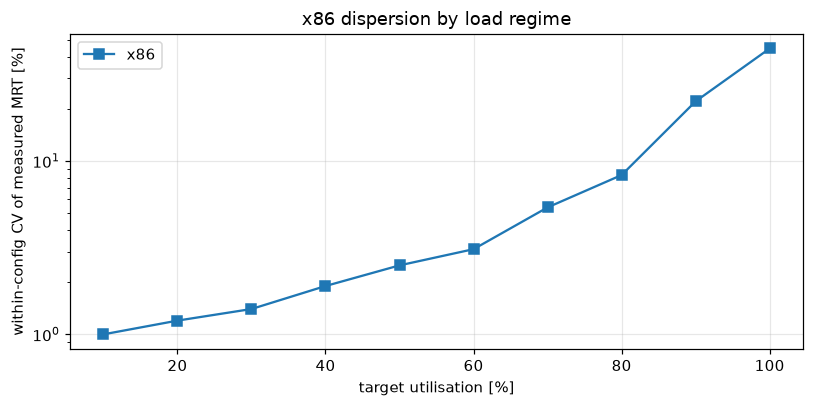

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(disp.index, disp["x86"], marker="s", label="x86")
ax.set_yscale("log")
ax.set_xlabel("target utilisation [%]")
ax.set_ylabel("within-config CV of measured MRT [%]")
ax.set_title("x86 dispersion by load regime")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Regime-aware multivariate screen

Subtract each configuration's feature median, scale residuals within the same target-load regime, and compute robust Mahalanobis distances with minimum covariance determinant. Flags use the robust z-score of `log10(D²)` and the configured threshold. A global-scale screen on the same x86 data is shown for comparison.

In [15]:
def layer_C(df, M, features, z_threshold=None, regime_aware=True):
    z_threshold = CONFIG["mcd_z_threshold"] if z_threshold is None else z_threshold
    cfg_cols = [M[k] for k in CONFIG_KEYS if M[k]]
    feats = [k for k in features if M[k] and not df[M[k]].isna().all()]
    regime = df[M[REGIME_KEY]]

    residuals = pd.DataFrame(index=df.index)
    for k in feats:
        x = df[M[k]].astype(float)
        resid = x - x.groupby([df[c] for c in cfg_cols]).transform("median")

        if regime_aware:
            scale = resid.groupby(regime).transform(lambda v: mad(v.values))
            scale = scale.where(
                np.isfinite(scale) & (scale > 0), resid.groupby(regime).transform("std")
            )
        else:
            s = mad(resid.values)
            s = s if (np.isfinite(s) and s > 0) else np.nanstd(resid.values)
            scale = pd.Series(s, index=df.index)

        residuals[k] = resid / scale.replace(0, np.nan)

    valid = residuals.dropna()
    out = pd.DataFrame(index=df.index)
    out["C_mahal"], out["C_z"], out["C_flag"] = np.nan, np.nan, False
    if valid.shape[0] <= valid.shape[1] + 5:
        return out, feats

    try:
        d = (
            MinCovDet(random_state=CONFIG["random_state"])
            .fit(valid.values)
            .mahalanobis(valid.values)
        )
    except Exception:  # singular covariance -> pseudo-inverse
        centre = valid.mean().values
        cov = np.cov(valid.values, rowvar=False) + np.eye(valid.shape[1]) * 1e-6
        dv = valid.values - centre
        d = np.einsum("ij,jk,ik->i", dv, np.linalg.pinv(cov), dv)

    out.loc[valid.index, "C_mahal"] = d
    out.loc[valid.index, "C_z"] = robust_z(np.log10(d + 1e-9))
    out.loc[valid.index, "C_flag"] = out.loc[valid.index, "C_z"] > z_threshold
    return out, feats

In [16]:
C_results = {}
rates = {}

for plat, df in datasets.items():
    M = COLS[plat]
    new, _ = layer_C(df, M, FEATURES[plat], regime_aware=True)
    old, _ = layer_C(raw[plat], M, FEATURES[plat], regime_aware=False)
    C_results[plat] = new

    util_raw, util_new = raw[plat][M[REGIME_KEY]], df[M[REGIME_KEY]]
    n = util_new.groupby(util_new).size()
    rates[(plat, "global [%]")] = (
        100 * old["C_flag"].groupby(util_raw).sum() / util_raw.groupby(util_raw).size()
    ).round(1)
    rates[(plat, "regime-aware [%]")] = (
        100 * new["C_flag"].groupby(util_new).sum() / n
    ).round(1)

rate_table = pd.DataFrame(rates)
rate_table.index.name = "target utilisation [%]"
rate_table

x86                 
                       global [%] regime-aware [%]
target utilisation [%]                            
10                          0.000            0.800
20                          0.000            0.200
30                          0.000            0.200
40                          0.000            0.800
50                          0.000            1.400
60                          0.000            0.600
70                          0.000            1.200
80                          0.000            0.200
90                          1.000            0.600
100                        24.800            0.000

Global-scale flags concentrate at the highest target load. Statistical flags alone do not distinguish measurement defects from queueing variability.

## 6. Screen audit

Material flags must exceed both the multivariate threshold and the 10% relative-deviation floor. The overlap table separates flags already explained by structural checks from additional flagged rows. This section changes no data.

In [17]:
def deviation_profile(df, M, features):
    """Per-row, per-feature relative deviation from the configuration median."""
    cfg_cols = [M[k] for k in CONFIG_KEYS if M[k]]
    prof = pd.DataFrame(index=df.index)
    for k in features:
        col = M[k]
        if col is None or df[col].isna().all():
            continue
        x = df[col].astype(float)
        med = x.groupby([df[c] for c in cfg_cols]).transform("median")
        prof[col] = (x - med).abs() / med.abs().replace(0, np.nan)
    return prof


for plat, df in datasets.items():
    prof = deviation_profile(df, COLS[plat], FEATURES[plat])
    scored = prof.notna().any(axis=1)
    driver = pd.Series(np.nan, index=prof.index, dtype=object)
    driver.loc[scored] = prof.loc[scored].idxmax(axis=1)

    C_results[plat]["C_max_rel_dev"] = prof.max(axis=1)
    C_results[plat]["C_driver"] = driver
    C_results[plat]["C_material"] = C_results[plat]["C_flag"] & (
        C_results[plat]["C_max_rel_dev"] > CONFIG["min_rel_deviation"]
    )

overlap = {}
for plat in datasets:
    A, C = A_results[plat], C_results[plat]
    structural = A["A_hard"] | A["A_target"] | A["A_run"] | A["A_stationary"]
    overlap[plat] = {
        "Layer C flags": int(C["C_flag"].sum()),
        "clear effect-size floor": int(C["C_material"].sum()),
        "also caught structurally": int((C["C_material"] & structural).sum()),
        "UNIQUE to Layer C": int((C["C_material"] & ~structural).sum()),
        "structural rows C missed": int((structural & ~C["C_flag"]).sum()),
        "removals attributable to C": 0,
    }

pd.DataFrame(overlap)

,x86
Layer C flags,30
clear effect-size floor,27
also caught structurally,17
UNIQUE to Layer C,10
structural rows C missed,33
removals attributable to C,0


In [18]:
# Everything the screen finds that no structural rule explains.
residual = []
for plat, df in datasets.items():
    M, A, C = COLS[plat], A_results[plat], C_results[plat]
    structural = A["A_hard"] | A["A_target"] | A["A_run"] | A["A_stationary"]
    cfg_cols = [M[k] for k in CONFIG_KEYS if M[k]]

    for i in df.index[C["C_material"] & ~structural]:
        row = df.loc[i]
        peers = df[(df[cfg_cols] == row[cfg_cols]).all(axis=1) & (df.index != i)]
        drv = C.loc[i, "C_driver"]
        residual.append(
            {
                "platform": plat,
                "row": i,
                "cfg_util": row[M["cfg_util"]],
                "driver": drv[:28],
                "value": round(row[drv], 2),
                "peer median": round(peers[drv].median(), 2),
                "ratio": round(row[drv] / peers[drv].median(), 3),
                "arrival window": round(row[M["interarr"]] * row[M["meas_lambda"]], 3),
                "util - target": round(row[M["meas_util"]] - row[M["cfg_util"]], 1),
            }
        )

pd.DataFrame(residual)

,platform,row,cfg_util,driver,value,peer median,ratio,arrival window,util - target
0,x86,202,10.000,Measured CORE Power [W],3.720,1.440,2.583,1.004,-0.100
1,x86,205,10.000,Measured CORE Power [W],5.370,1.440,3.729,0.996,-0.700
2,x86,246,50.000,Measured MRT [ms],209.890,185.880,1.129,1.021,6.700
3,x86,265,70.000,Measured MRT [ms],327.470,284.600,1.151,0.979,3.500
4,x86,460,70.000,Measured MRT [ms],349.620,275.730,1.268,1.015,5.900
5,x86,466,70.000,Measured MRT [ms],364.820,275.730,1.323,0.970,7.200
6,x86,1643,50.000,Measured MRT [ms],211.840,192.110,1.103,1.010,5.800
7,x86,3655,60.000,Measured MRT [ms],247.350,218.880,1.130,1.018,4.800
8,x86,4164,70.000,Measured MRT [ms],362.690,271.030,1.338,0.973,7.600
9,x86,4663,70.000,Measured MRT [ms],337.220,297.970,1.132,0.989,4.400


Additional material multivariate flags are retained unless another exclusion rule applies. Their effect is assessed in the conservative sensitivity variant; statistical flags do not establish measurement corruption.

## 7. Row disposition and stationary dataset

Physical/identity failures, off-target runs, arrival-consistency failures, and estimated $\rho\ge1$ are excluded from the stationary dataset in that order. `excluded_nonstationary` identifies a model-applicability exclusion, not corruption. All input rows remain in the audit. Missing service moments do not remove otherwise usable measurements.

In [19]:
PRIORITY = [
    "removed_corrupt",
    "removed_off_target",
    "removed_bad_run",
    "excluded_nonstationary",
    "flagged_model",
    "flagged_soft",
    "ok",
]


def build_report(df, plat):
    M, A, C = COLS[plat], A_results[plat], C_results[plat]

    rep = pd.DataFrame(index=df.index)
    rep["platform"], rep["row"] = plat, df.index
    for k in CONFIG_KEYS:
        if M[k]:
            rep[k] = df[M[k]].values

    rep["label_repaired"] = (
        df.index.isin(label_repairs[plat]["row"]) & CONFIG["repair_labels"]
    )
    rep["A_hard"], rep["A_target"], rep["A_run"] = (
        A["A_hard"],
        A["A_target"],
        A["A_run"],
    )
    rep["A_model"], rep["A_soft"], rep["A_stationary"] = (
        A["A_model"],
        A["A_soft"],
        A["A_stationary"],
    )
    rep["C_flag"], rep["C_material"] = C["C_flag"], C["C_material"]
    rep["C_z"] = C["C_z"].round(2)
    rep["C_max_rel_dev"] = C["C_max_rel_dev"].round(4)
    rep["C_driver"] = C["C_driver"]

    rep["disposition"] = np.select(
        [
            A["A_hard"],
            A["A_target"],
            A["A_run"],
            A["A_stationary"],
            A["A_model"],
            A["A_soft"],
        ],
        [
            "removed_corrupt",
            "removed_off_target",
            "removed_bad_run",
            "excluded_nonstationary",
            "flagged_model",
            "flagged_soft",
        ],
        default="ok",
    )
    rep["removed"] = rep["disposition"].str.startswith("removed") | rep["disposition"].eq("excluded_nonstationary")
    for column in ("rho_implied", "service_cs2", "pk_available", "pk_status", "pk_mrt_ms", "little_mrt_ms", "pk_lower_ms", "pk_upper_ms"):
        rep[column] = REFERENCES[plat][column]

    reasons = []
    for i in df.index:
        r = list(A["A_reasons"][i])
        if rep["label_repaired"][i]:
            r.insert(0, "label repaired in §2")
        if bool(C["C_material"].get(i, False)):
            r.append(f"[screen only] multivariate residual (z={C['C_z'][i]:.1f})")
        reasons.append("; ".join(r))
    rep["reasons"] = reasons
    return rep


reports = {plat: build_report(df, plat) for plat, df in datasets.items()}
report_all = pd.concat(reports.values(), ignore_index=True)

summary = (
    report_all.groupby(["platform", "disposition"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=PRIORITY, fill_value=0)
)
summary["total"] = summary.sum(axis=1)
summary

disposition,removed_corrupt,removed_off_target,removed_bad_run,excluded_nonstationary,flagged_model,flagged_soft,ok,total
platform,,,,,,,,
x86,0,0,20,30,0,693,4256,4999


In [20]:
clean = {}
for plat, df in datasets.items():
    keep = ~reports[plat]["removed"]
    clean[plat] = df.loc[keep].copy()
    clean[plat]["disposition"] = reports[plat].loc[keep, "disposition"]
    print(f"{plat}: {len(df):,} input -> {len(clean[plat]):,} stationary-analysis rows; {int((~keep).sum()):,} exclusions")
    print("Raw measurements modified: 0")

x86: 4,999 input -> 4,949 stationary-analysis rows; 50 exclusions
Raw measurements modified: 0


## 8. Sensitivity analysis

| Variant | Data included |
|---|---|
| `full` | All input rows |
| `clean` | Stationary-analysis rows after integrity checks |
| `conservative` | Clean data excluding material multivariate flags |

Targets are configured settings, not measured $\rho$. Saturated input rows remain available in `full` and the complete audit. NaN indicates no eligible observations or unavailable PK evidence.

In [21]:
def headline(df, M):
    util = df[M[REGIME_KEY]]
    return pd.Series(
        {
            "mean MRT @ target=10 [ms]": df.loc[util == 10, M["meas_mrt"]].mean(),
            "sd MRT @ target=10 [ms]": df.loc[util == 10, M["meas_mrt"]].std(),
            "mean MRT @ target=50 [ms]": df.loc[util == 50, M["meas_mrt"]].mean(),
            "mean MRT @ target=100 [ms]": df.loc[util == 100, M["meas_mrt"]].mean(),
            "sd MRT @ target=100 [ms]": df.loc[util == 100, M["meas_mrt"]].std(),
            "mean |measured-Little| [ms]": (df[M["meas_mrt"]] - REFERENCES["x86"].loc[df.index,"little_mrt_ms"]).abs().mean(),
            "mean |measured-PK| [ms]": (df[M["meas_mrt"]] - REFERENCES["x86"].loc[df.index,"pk_mrt_ms"]).abs().mean(),
            "n rows": len(df),
        }
    )


def sensitivity_frames(plat):
    df, M, rep = datasets[plat], COLS[plat], reports[plat]
    return {
        "full": df,
        "clean": clean[plat],
        "conservative": df.loc[~(rep["removed"] | rep["C_material"]).values],
    }


sensitivity = pd.DataFrame(
    {
        (plat, variant): headline(d, COLS[plat])
        for plat in datasets
        for variant, d in sensitivity_frames(plat).items()
    }
).round(3)
sensitivity

x86                       
                                 full     clean conservative
mean MRT @ target=10 [ms]     129.852   129.879      129.877
sd MRT @ target=10 [ms]         1.404     1.362        1.363
mean MRT @ target=50 [ms]     187.996   187.934      187.841
mean MRT @ target=100 [ms]  2,272.898 2,077.057    2,077.057
sd MRT @ target=100 [ms]    1,270.876   891.916      891.916
mean |measured-Little| [ms]     9.127     7.559        7.556
mean |measured-PK| [ms]           NaN       NaN          NaN
n rows                      4,999.000 4,949.000    4,939.000

In [22]:
shift = {}
for plat in datasets:
    base = sensitivity[(plat, "clean")]
    for variant in ("full", "conservative"):
        shift[(plat, f"{variant} vs clean [%]")] = 100 * (
            sensitivity[(plat, variant)] / base - 1
        )

pd.DataFrame(shift).drop(index="n rows").round(2)

x86                          
                            full vs clean [%] conservative vs clean [%]
mean MRT @ target=10 [ms]              -0.020                    -0.000
sd MRT @ target=10 [ms]                 3.080                     0.070
mean MRT @ target=50 [ms]               0.030                    -0.050
mean MRT @ target=100 [ms]              9.430                     0.000
sd MRT @ target=100 [ms]               42.490                     0.000
mean |measured-Little| [ms]            20.740                    -0.040
mean |measured-PK| [ms]                   NaN                       NaN

## 9. Validation and export

Export the stationary-analysis dataset, complete run-level audit, per-check status, and conditional model references. Raw source measurements remain unchanged after header normalization and removal of the obsolete response-time reference.

In [23]:
# Check that cleaning preserves every retained measured value.
for plat, original in raw.items():
    target_column = COLS[plat]["cfg_util"]
    measured_columns = [c for c in original.columns if c != target_column]
    pd.testing.assert_frame_equal(
        datasets[plat][measured_columns], original[measured_columns]
    )
    pd.testing.assert_frame_equal(
        clean[plat][measured_columns], original.loc[clean[plat].index, measured_columns]
    )
    assert len(clean[plat]) + int(reports[plat]["removed"].sum()) == len(original)
assert report_all["disposition"].notna().all()
print("Validation passed: retained measurements and row counts reconcile.")

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

for plat in datasets:
    clean[plat].to_csv(OUT_DIR / f"{plat.lower()}_mg1_clean.csv", index=False)
    reports[plat].to_csv(OUT_DIR / f"{plat.lower()}_mg1_audit.csv", index=False)
    if len(label_repairs[plat]):
        label_repairs[plat].to_csv(
            OUT_DIR / f"{plat.lower()}_label_repairs.csv", index=False
        )

report_all.to_csv(OUT_DIR / "audit_all.csv", index=False)
A_status["x86"].to_csv(OUT_DIR / "x86_mg1_check_status.csv", index_label="row")
REFERENCES["x86"].to_csv(OUT_DIR / "x86_mg1_references.csv", index_label="row")
assert not (REFERENCES["x86"]["pk_available"] & REFERENCES["x86"]["pk_mrt_ms"].isna()).any()
assert not (REFERENCES["x86"]["service_cs2"].isna() & REFERENCES["x86"]["pk_available"]).any()
assert (REFERENCES["x86"].loc[REFERENCES["x86"]["pk_available"], "pk_mrt_ms"] >= REFERENCES["x86"].loc[REFERENCES["x86"]["pk_available"], "service_mean_ms"]).all()
assert (REFERENCES["x86"].loc[clean["x86"].index,"rho_implied"] < 1).all()

export_paths = [OUT_DIR / "x86_mg1_clean.csv", OUT_DIR / "x86_mg1_audit.csv", OUT_DIR / "audit_all.csv"]
for p in export_paths:
    print(f"  {p.name:<34} {p.stat().st_size / 1024:>8.1f} KB")
import json
import platform
from importlib.metadata import version

provenance = {
    "queueing_model": "stationary FCFS M/G/1 (conditional diagnostics)",
    "inputs": SOURCE_RECORDS,
    "parameters": CONFIG,
    "python_version": platform.python_version(),
    "packages": {
        name: version(name)
        for name in ("numpy", "pandas", "scikit-learn", "matplotlib")
    },
    "rows": {
        plat: {
            "input": len(raw[plat]),
            "retained": len(clean[plat]),
            "removed": int(reports[plat]["removed"].sum()),
            "labels_repaired": int(reports[plat]["label_repaired"].sum()),
        }
        for plat in raw
    },
}
(OUT_DIR / "provenance.json").write_text(json.dumps(provenance, indent=2))

Validation passed: retained measurements and row counts reconcile.


  x86_mg1_clean.csv                     492.6 KB
  x86_mg1_audit.csv                    1035.3 KB
  audit_all.csv                        1035.3 KB


985

In [24]:
print("PROVENANCE — everything this notebook did to the data")
print("=" * 66)
for plat in datasets:
    log, rep = label_repairs[plat], reports[plat]
    print(f"\n{plat}")
    print(f"  labels repaired      : {len(log)}")
    if len(log):
        moves = log.groupby(["stored_label", "repaired_label"]).size()
        print(
            f"    stored -> repaired : {dict(list(moves.items())[:4])}"
            f"{' ...' if len(moves) > 4 else ''}"
        )
    print(f"  rows excluded         : {int(rep['removed'].sum())}")
    for d, n in rep.loc[rep["removed"], "disposition"].value_counts().items():
        print(f"    {d:<20} {n}")
    print(
        f"  rows kept but flagged: {int((~rep['removed'] & rep['C_material']).sum())} (screen only)"
    )

print(f"\nMEASUREMENT VALUES MODIFIED: 0")
print(f"Rows with no disposition  : {int(report_all['disposition'].isna().sum())}")

PROVENANCE — everything this notebook did to the data

x86
  labels repaired      : 0
  rows excluded         : 50
    excluded_nonstationary 30
    removed_bad_run      20
  rows kept but flagged: 10 (screen only)

MEASUREMENT VALUES MODIFIED: 0
Rows with no disposition  : 0
